In [2]:

# ============================================
# InfraGuard AI | Cell 1
# Install Required Libraries
# ============================================

import sys
import importlib.util
import subprocess

required_packages = {
    "datasets": "datasets>=3.0.0",
    "tqdm": "tqdm",
    "matplotlib": "matplotlib",
    "PIL": "Pillow"
}

for module, package in required_packages.items():

    if importlib.util.find_spec(module) is None:

        print(f"Installing {package}...")

        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            package
        ])

    else:
        print(f"{module}: Already installed")

print("\nAll required libraries are ready!")


datasets: Already installed
tqdm: Already installed
matplotlib: Already installed
PIL: Already installed

All required libraries are ready!


In [3]:

# ============================================
# InfraGuard AI | Cell 2
# Environment Initialization
# ============================================

import os
import sys
import json
import random
import shutil
import zipfile
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from collections import Counter

from tqdm.auto import tqdm
from datasets import load_dataset

print("=" * 55)
print("             INFRAGUARD AI")
print("          ENVIRONMENT INITIALIZATION")
print("=" * 55)

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

import datasets
print("Hugging Face Datasets:", datasets.__version__)

try:
    import torch
    import torchvision

    print("PyTorch:", torch.__version__)
    print("Torchvision:", torchvision.__version__)

    if torch.cuda.is_available():

        print("\nGPU Available: True")
        print("GPU Count:", torch.cuda.device_count())

        for i in range(torch.cuda.device_count()):
            print(
                f"GPU {i}:",
                torch.cuda.get_device_name(i)
            )

    else:
        print("\nGPU Available: False")
        print("Dataset preparation can still run on CPU.")

except ImportError:
    print("PyTorch check skipped.")

print("\nEnvironment initialization completed!")


             INFRAGUARD AI
          ENVIRONMENT INITIALIZATION
Python: 3.13.18
NumPy: 2.1.3
Pandas: 2.3.3
Hugging Face Datasets: 4.8.5
PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu

GPU Available: False
Dataset preparation can still run on CPU.

Environment initialization completed!


In [4]:

# ============================================
# InfraGuard AI | Cell 3
# Project Directory Setup
# ============================================

PROJECT_ROOT = Path(
    "/kaggle/working/InfraGuard-AI"
)

DATA_ROOT = (
    PROJECT_ROOT /
    "data" /
    "cif_subset_v02"
)

IMAGE_ROOT = DATA_ROOT / "images"
ANNOTATION_ROOT = DATA_ROOT / "annotations"

RESULTS_ROOT = PROJECT_ROOT / "results"
DOCS_ROOT = PROJECT_ROOT / "docs"
CONFIG_ROOT = PROJECT_ROOT / "configs"

folders = [
    IMAGE_ROOT / "train",
    IMAGE_ROOT / "val",
    IMAGE_ROOT / "test",
    ANNOTATION_ROOT,
    RESULTS_ROOT,
    DOCS_ROOT,
    CONFIG_ROOT
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

os.chdir(PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)
print("\nCreated directories:")

for folder in folders:
    print("OK:", folder.relative_to(PROJECT_ROOT))

print("\nDirectory setup completed!")


Project root: /kaggle/working/InfraGuard-AI

Created directories:
OK: data/cif_subset_v02/images/train
OK: data/cif_subset_v02/images/val
OK: data/cif_subset_v02/images/test
OK: data/cif_subset_v02/annotations
OK: results
OK: docs
OK: configs

Directory setup completed!


In [5]:

# ============================================
# InfraGuard AI | Cell 4
# Dataset Configuration
# ============================================

DATASET_ID = "ibm-research/cif-dataset"

SEED = 42

CATEGORY_NAMES = {
    1: "Algae",
    2: "Crack",
    3: "Net-Crack",
    4: "Crack with Precipitation",
    5: "Rust",
    6: "Spalling"
}

SPLITS = {
    "train": {
        "config": "train_tiled",
        "count": 500
    },

    "val": {
        "config": "val_tiled",
        "count": 100
    },

    "test": {
        "config": "test_tiled",
        "count": 100
    }
}

print("Dataset:", DATASET_ID)

print("\nDefect Categories:")

for category_id, name in CATEGORY_NAMES.items():
    print(category_id, ":", name)

print("\nExperimental split plan:")

for split, config in SPLITS.items():
    print(
        split,
        "|",
        config["config"],
        "|",
        config["count"],
        "images"
    )


Dataset: ibm-research/cif-dataset

Defect Categories:
1 : Algae
2 : Crack
3 : Net-Crack
4 : Crack with Precipitation
5 : Rust
6 : Spalling

Experimental split plan:
train | train_tiled | 500 images
val | val_tiled | 100 images
test | test_tiled | 100 images


In [6]:

# ============================================
# InfraGuard AI | Cell 5
# Connect to CiF Dataset
# ============================================

train_stream = load_dataset(
    DATASET_ID,
    "train_tiled",
    split="train",
    streaming=True
)

print("CiF training dataset connected successfully!")

print("\nDataset object:")
print(type(train_stream))


README.md:   0%|          | 0.00/7.25k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/188 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/78 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/76 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/80 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/80 [00:00<?, ?it/s]

CiF training dataset connected successfully!

Dataset object:
<class 'datasets.iterable_dataset.IterableDataset'>


In [7]:

# ============================================
# InfraGuard AI | Cell 6
# Sample Inspection
# ============================================

preview_stream = load_dataset(
    DATASET_ID,
    "train_tiled",
    split="train",
    streaming=True
)

sample = next(iter(preview_stream))

print("IMAGE INFORMATION")
print("-" * 40)

print("Image ID:", sample["image_id"])
print("File name:", sample["file_name"])
print("Width:", sample["width"])
print("Height:", sample["height"])

print("\nIMAGE SIZE:", sample["image"].size)

objects = sample["objects"]

print("\nANNOTATION INFORMATION")
print("-" * 40)

print("Annotation fields:", objects.keys())

print(
    "Number of instances:",
    len(objects["category_id"])
)

print("\nDefect categories:")

for category_id in objects["category_id"]:
    print(
        category_id,
        "->",
        CATEGORY_NAMES.get(int(category_id), "Unknown")
    )

print("\nBounding box example:")
if objects["bbox"]:
    print(objects["bbox"][0])

print("\nSegmentation example:")
if objects["segmentation"]:
    print(objects["segmentation"][0][:1])

print("\nSample inspection completed!")


Resolving data files:   0%|          | 0/188 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/78 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/76 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/80 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/80 [00:00<?, ?it/s]

IMAGE INFORMATION
----------------------------------------
Image ID: 10000001
File name: DJI_20221118111015_0027_SUPR_0_0.JPG
Width: 1024
Height: 1024

IMAGE SIZE: (1024, 1024)

ANNOTATION INFORMATION
----------------------------------------
Annotation fields: dict_keys(['id', 'category_id', 'bbox', 'area', 'iscrowd', 'segmentation'])
Number of instances: 1

Defect categories:
2 -> Crack

Bounding box example:
[609.0, 676.0, 91.0, 120.0]

Segmentation example:
[[609.0, 676.0, 609.0, 678.0, 610.0, 679.0, 610.0, 681.0, 611.0, 682.0, 611.0, 683.0, 613.0, 685.0, 613.0, 686.0, 615.0, 688.0, 615.0, 689.0, 617.0, 691.0, 617.0, 692.0, 619.0, 694.0, 619.0, 695.0, 621.0, 697.0, 621.0, 698.0, 626.0, 703.0, 626.0, 704.0, 627.0, 705.0, 627.0, 706.0, 634.0, 713.0, 635.0, 713.0, 636.0, 714.0, 637.0, 714.0, 644.0, 721.0, 646.0, 721.0, 656.0, 731.0, 656.0, 732.0, 657.0, 733.0, 657.0, 734.0, 659.0, 736.0, 660.0, 736.0, 666.0, 742.0, 666.0, 743.0, 674.0, 751.0, 675.0, 751.0, 684.0, 760.0, 684.0, 761.0, 6

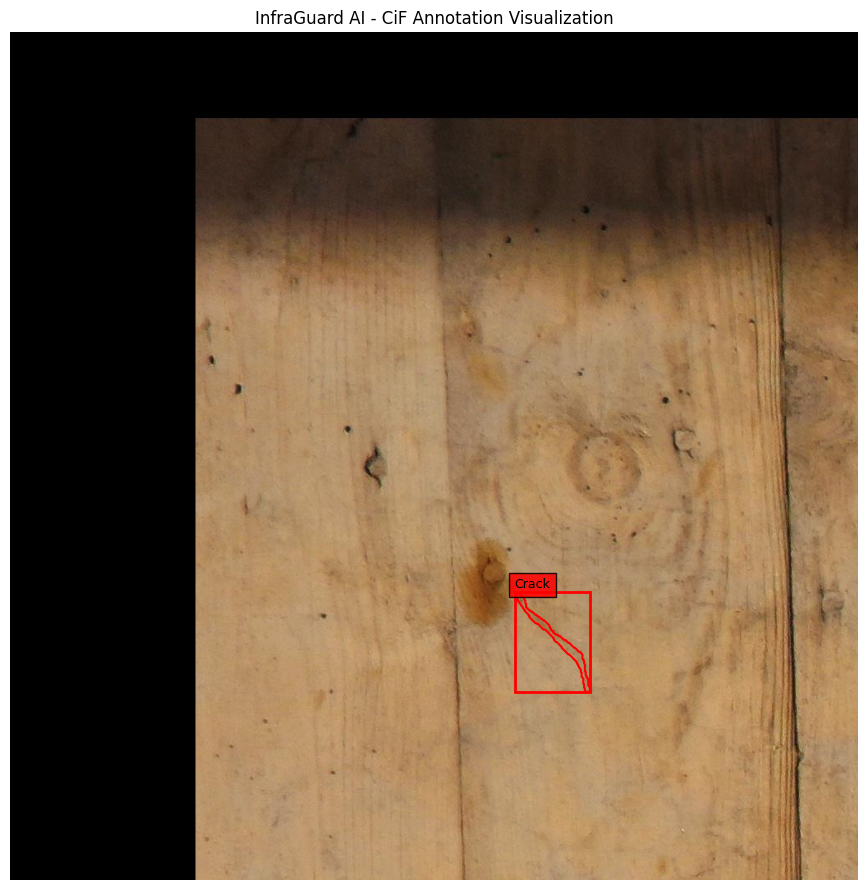

In [8]:

# ============================================
# InfraGuard AI | Cell 7
# Image and Annotation Visualization
# ============================================

from matplotlib.patches import Rectangle, Polygon

image = sample["image"].convert("RGB")

objects = sample["objects"]

fig, ax = plt.subplots(figsize=(14, 9))

ax.imshow(image)

colors = {
    1: "lime",
    2: "red",
    3: "yellow",
    4: "cyan",
    5: "orange",
    6: "magenta"
}

for i, category_id in enumerate(objects["category_id"]):

    category_id = int(category_id)

    color = colors.get(category_id, "white")

    label = CATEGORY_NAMES.get(
        category_id,
        "Unknown"
    )

    x, y, w, h = objects["bbox"][i]

    # Bounding box
    rect = Rectangle(
        (x, y),
        w,
        h,
        linewidth=2,
        edgecolor=color,
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x,
        max(0, y - 5),
        label,
        color="black",
        fontsize=9,
        bbox=dict(
            facecolor=color,
            alpha=0.85
        )
    )

    # Segmentation polygons
    polygons = objects["segmentation"][i] or []

    for polygon in polygons:

        coords = np.asarray(
            polygon,
            dtype=float
        )

        if len(coords) < 6 or len(coords) % 2 != 0:
            continue

        coords = coords.reshape(-1, 2)

        poly = Polygon(
            coords,
            closed=True,
            fill=False,
            edgecolor=color,
            linewidth=1.5
        )

        ax.add_patch(poly)

ax.set_title(
    "InfraGuard AI - CiF Annotation Visualization"
)

ax.axis("off")

plt.tight_layout()
plt.show()


In [9]:

# ============================================
# InfraGuard AI | Cell 8
# Sampling Configuration
# ============================================

TRAIN_COUNT = 500
VAL_COUNT = 100
TEST_COUNT = 100

SHUFFLE_BUFFER = 1024

EXPECTED_COUNTS = {
    "train": TRAIN_COUNT,
    "val": VAL_COUNT,
    "test": TEST_COUNT
}

print("Sampling strategy initialized")

print("Random seed:", SEED)
print("Shuffle buffer:", SHUFFLE_BUFFER)

print("\nTarget image counts:")

for split, count in EXPECTED_COUNTS.items():
    print(split, ":", count)

print("\nTotal:", sum(EXPECTED_COUNTS.values()))


Sampling strategy initialized
Random seed: 42
Shuffle buffer: 1024

Target image counts:
train : 500
val : 100
test : 100

Total: 700


In [10]:

# ============================================
# InfraGuard AI | Cell 9
# Dataset Builder
# ============================================

import math

def clean_polygons(raw_polygons):

    if raw_polygons is None:
        return []

    # Handle a single flat polygon if encountered
    if len(raw_polygons) > 0 and isinstance(
        raw_polygons[0],
        (int, float, np.number)
    ):
        raw_polygons = [raw_polygons]

    valid_polygons = []

    for polygon in raw_polygons:

        coords = np.asarray(
            polygon,
            dtype=np.float64
        ).reshape(-1)

        if len(coords) < 6:
            continue

        if len(coords) % 2 != 0:
            continue

        if not np.isfinite(coords).all():
            continue

        valid_polygons.append(
            coords.tolist()
        )

    return valid_polygons


def prepare_split(split_name, config_name, target_count):

    print("\n" + "=" * 55)
    print("PREPARING:", split_name.upper())
    print("=" * 55)

    stream = load_dataset(
        DATASET_ID,
        config_name,
        split="train",
        streaming=True
    )

    stream = stream.shuffle(
        seed=SEED,
        buffer_size=SHUFFLE_BUFFER
    )

    image_dir = IMAGE_ROOT / split_name

    coco = {
        "info": {
            "description": "InfraGuard AI CiF subset",
            "version": "0.2",
            "split": split_name,
            "seed": SEED
        },

        "licenses": [],

        "images": [],

        "annotations": [],

        "categories": [
            {
                "id": cid,
                "name": name,
                "supercategory": "infrastructure_defect"
            }

            for cid, name in CATEGORY_NAMES.items()
        ]
    }

    class_counts = Counter()

    skipped_annotations = 0
    images_without_annotations = 0

    for image_index, item in enumerate(
        tqdm(
            stream.take(target_count),
            total=target_count,
            desc=split_name
        ),
        start=1
    ):

        image = item["image"].convert("RGB")

        width, height = image.size

        filename = f"{image_index:06d}.jpg"

        image_path = image_dir / filename

        image.save(
            image_path,
            format="JPEG",
            quality=95
        )

        local_image_id = image_index

        coco["images"].append({
            "id": local_image_id,

            "file_name": (
                f"images/{split_name}/{filename}"
            ),

            "width": width,
            "height": height,

            "source_image_id": int(item["image_id"]),

            "source_file_name": item["file_name"]
        })

        objects = item["objects"]

        required_fields = [
            "category_id",
            "bbox",
            "area",
            "iscrowd",
            "segmentation"
        ]

        instance_count = len(objects["category_id"])

        for field in required_fields:

            if len(objects[field]) != instance_count:
                raise ValueError(
                    f"Annotation length mismatch: {field}"
                )

        valid_before = len(coco["annotations"])

        for j in range(instance_count):

            category_id = int(
                objects["category_id"][j]
            )

            if category_id not in CATEGORY_NAMES:
                skipped_annotations += 1
                continue

            bbox = [
                float(v)
                for v in objects["bbox"][j]
            ]

            if len(bbox) != 4:
                skipped_annotations += 1
                continue

            x, y, box_w, box_h = bbox

            if (
                not all(math.isfinite(v) for v in bbox)
                or x < 0
                or y < 0
                or box_w <= 0
                or box_h <= 0
                or x + box_w > width + 1
                or y + box_h > height + 1
            ):
                skipped_annotations += 1
                continue

            polygons = clean_polygons(
                objects["segmentation"][j]
            )

            if not polygons:
                skipped_annotations += 1
                continue

            area = float(objects["area"][j])

            if not math.isfinite(area) or area <= 0:
                skipped_annotations += 1
                continue

            annotation = {
                "id": len(coco["annotations"]) + 1,

                "image_id": local_image_id,

                "category_id": category_id,

                "bbox": bbox,

                "area": area,

                "iscrowd": int(
                    objects["iscrowd"][j]
                ),

                "segmentation": polygons
            }

            coco["annotations"].append(annotation)

            class_counts[category_id] += 1

        if len(coco["annotations"]) == valid_before:
            images_without_annotations += 1

    actual_count = len(coco["images"])

    if actual_count != target_count:

        raise RuntimeError(
            f"{split_name}: Expected {target_count}, "
            f"but received {actual_count}"
        )

    annotation_path = (
        ANNOTATION_ROOT /
        f"{split_name}.json"
    )

    with open(annotation_path, "w") as f:

        json.dump(
            coco,
            f,
            indent=2,
            allow_nan=False
        )

    result = {
        "images": actual_count,

        "instances": len(coco["annotations"]),

        "class_distribution": {
            CATEGORY_NAMES[cid]: class_counts[cid]
            for cid in CATEGORY_NAMES
        },

        "skipped_annotations": skipped_annotations,

        "images_without_annotations": (
            images_without_annotations
        )
    }

    print("\nSplit completed:", split_name)
    print("Images:", actual_count)
    print("Instances:", len(coco["annotations"]))
    print("Skipped:", skipped_annotations)

    return result


print("Dataset builder is ready!")


Dataset builder is ready!


In [11]:

# ============================================
# InfraGuard AI | Cell 10
# Generate Train, Validation and Test
# ============================================

dataset_summary = {}

for split_name, config in SPLITS.items():

    result = prepare_split(
        split_name=split_name,
        config_name=config["config"],
        target_count=config["count"]
    )

    dataset_summary[split_name] = result

print("\n" + "=" * 55)
print("ALL DATASET SPLITS GENERATED")
print("=" * 55)

for split, result in dataset_summary.items():

    print(
        f"{split.upper()}: "
        f"{result['images']} images | "
        f"{result['instances']} instances"
    )

print("\nDataset generation completed!")



PREPARING: TRAIN


Resolving data files:   0%|          | 0/188 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/78 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/76 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/80 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

... (18 outputs left out)

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

test:   0%|          | 0/100 [00:00<?, ?it/s]


Split completed: test
Images: 100
Instances: 110
Skipped: 0

ALL DATASET SPLITS GENERATED
TRAIN: 500 images | 557 instances
VAL: 100 images | 186 instances
TEST: 100 images | 110 instances

Dataset generation completed!


In [12]:

# ============================================
# InfraGuard AI | Cell 11
# Dataset Integrity Verification
# ============================================

from PIL import Image

verification_results = {}

for split_name, config in SPLITS.items():

    print("\n" + "=" * 50)
    print("VERIFYING:", split_name.upper())
    print("=" * 50)

    annotation_file = (
        ANNOTATION_ROOT /
        f"{split_name}.json"
    )

    assert annotation_file.exists(), (
        f"Missing annotation file: {annotation_file}"
    )

    with open(annotation_file) as f:
        data = json.load(f)

    images = data["images"]
    annotations = data["annotations"]

    image_ids = [
        item["id"] for item in images
    ]

    assert len(image_ids) == len(set(image_ids)), (
        "Duplicate image IDs found"
    )

    valid_image_ids = set(image_ids)

    missing_images = []
    invalid_references = []
    invalid_bboxes = []
    invalid_polygons = []

    for image_info in tqdm(images, desc="Checking images"):

        image_path = (
            DATA_ROOT /
            image_info["file_name"]
        )

        if not image_path.exists():
            missing_images.append(image_info["file_name"])
            continue

        with Image.open(image_path) as img:

            if img.size != (
                image_info["width"],
                image_info["height"]
            ):
                raise ValueError(
                    f"Image dimension mismatch: {image_path}"
                )

    for ann in annotations:

        if ann["image_id"] not in valid_image_ids:
            invalid_references.append(ann["id"])
            continue

        if ann["category_id"] not in CATEGORY_NAMES:
            raise ValueError(
                f"Unknown category: {ann['category_id']}"
            )

        x, y, w, h = ann["bbox"]

        if (
            x < 0 or y < 0
            or w <= 0 or h <= 0
            or not all(math.isfinite(v) for v in ann["bbox"])
        ):
            invalid_bboxes.append(ann["id"])

        for polygon in ann["segmentation"]:

            if (
                len(polygon) < 6
                or len(polygon) % 2 != 0
                or not np.isfinite(polygon).all()
            ):
                invalid_polygons.append(ann["id"])

    assert len(images) == config["count"]
    assert len(missing_images) == 0
    assert len(invalid_references) == 0
    assert len(invalid_bboxes) == 0
    assert len(invalid_polygons) == 0

    verification_results[split_name] = {
        "images": len(images),
        "annotations": len(annotations),
        "missing_images": len(missing_images),
        "invalid_references": len(invalid_references),
        "invalid_bboxes": len(invalid_bboxes),
        "invalid_polygons": len(invalid_polygons),
        "status": "PASSED"
    }

    print("Images:", len(images))
    print("Annotations:", len(annotations))
    print("Missing images:", len(missing_images))
    print("Invalid references:", len(invalid_references))
    print("Invalid bounding boxes:", len(invalid_bboxes))
    print("Invalid polygons:", len(invalid_polygons))

    print("STATUS: PASSED")

print("\nALL DATASET INTEGRITY CHECKS PASSED!")



VERIFYING: TRAIN


Checking images:   0%|          | 0/500 [00:00<?, ?it/s]

Images: 500
Annotations: 557
Missing images: 0
Invalid references: 0
Invalid bounding boxes: 0
Invalid polygons: 0
STATUS: PASSED

VERIFYING: VAL


Checking images:   0%|          | 0/100 [00:00<?, ?it/s]

Images: 100
Annotations: 186
Missing images: 0
Invalid references: 0
Invalid bounding boxes: 0
Invalid polygons: 0
STATUS: PASSED

VERIFYING: TEST


Checking images:   0%|          | 0/100 [00:00<?, ?it/s]

Images: 100
Annotations: 110
Missing images: 0
Invalid references: 0
Invalid bounding boxes: 0
Invalid polygons: 0
STATUS: PASSED

ALL DATASET INTEGRITY CHECKS PASSED!


In [13]:

# ============================================
# InfraGuard AI | Cell 12
# Final Dataset Summary
# ============================================

from collections import Counter

final_summary = {
    "project": "InfraGuard AI",
    "version": "0.2",
    "dataset": DATASET_ID,
    "seed": SEED,
    "shuffle_buffer": SHUFFLE_BUFFER,
    "sampling_method": "Hugging Face streaming buffer shuffle",
    "splits": {}
}

for split_name, config in SPLITS.items():

    annotation_file = (
        ANNOTATION_ROOT /
        f"{split_name}.json"
    )

    with open(annotation_file) as f:
        data = json.load(f)

    counts = Counter(
        ann["category_id"]
        for ann in data["annotations"]
    )

    class_distribution = {
        CATEGORY_NAMES[cid]: counts.get(cid, 0)
        for cid in CATEGORY_NAMES
    }

    final_summary["splits"][split_name] = {
        "images": len(data["images"]),
        "instances": len(data["annotations"]),
        "class_distribution": class_distribution
    }

final_summary["total_images"] = sum(
    x["images"]
    for x in final_summary["splits"].values()
)

final_summary["total_instances"] = sum(
    x["instances"]
    for x in final_summary["splits"].values()
)

# Save summary in dataset folder
summary_data_path = (
    DATA_ROOT / "dataset_summary.json"
)

with open(summary_data_path, "w") as f:
    json.dump(final_summary, f, indent=4)

# Save a copy in results folder
summary_results_path = (
    RESULTS_ROOT / "dataset_summary.json"
)

with open(summary_results_path, "w") as f:
    json.dump(final_summary, f, indent=4)

print(json.dumps(final_summary, indent=4))

print("\nSummary saved successfully!")
print("Dataset:", summary_data_path)
print("Results:", summary_results_path)


{
    "project": "InfraGuard AI",
    "version": "0.2",
    "dataset": "ibm-research/cif-dataset",
    "seed": 42,
    "shuffle_buffer": 1024,
    "sampling_method": "Hugging Face streaming buffer shuffle",
    "splits": {
        "train": {
            "images": 500,
            "instances": 557,
            "class_distribution": {
                "Algae": 209,
                "Crack": 299,
                "Net-Crack": 21,
                "Crack with Precipitation": 11,
                "Rust": 1,
                "Spalling": 16
            }
        },
        "val": {
            "images": 100,
            "instances": 186,
            "class_distribution": {
                "Algae": 30,
                "Crack": 15,
                "Net-Crack": 9,
                "Crack with Precipitation": 0,
                "Rust": 59,
                "Spalling": 73
            }
        },
        "test": {
            "images": 100,
            "instances": 110,
            "class_distribution": {

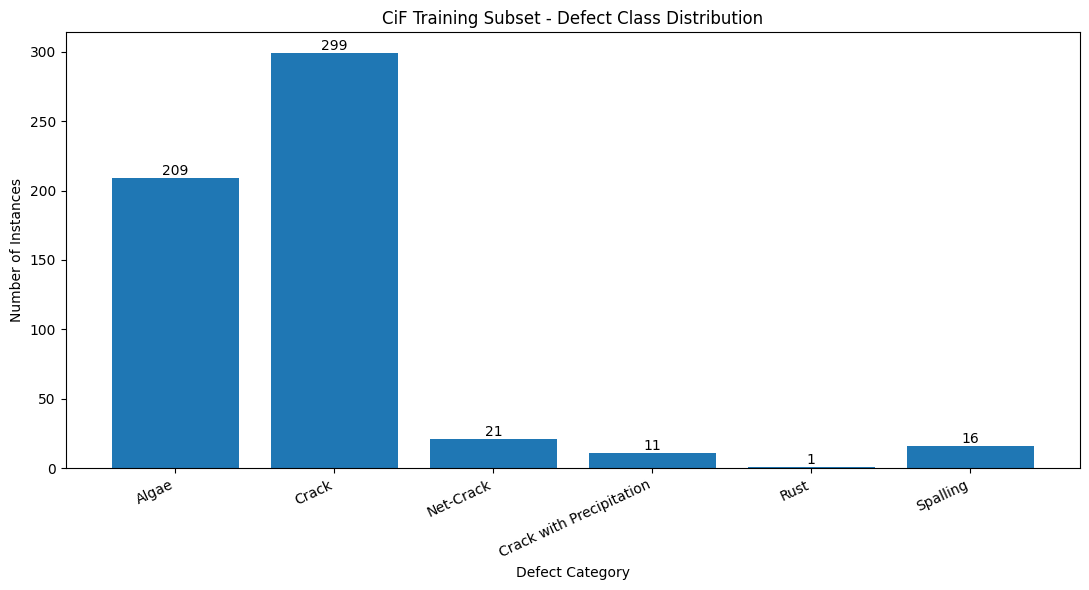

Chart saved: /kaggle/working/InfraGuard-AI/results/train_class_distribution.png


In [14]:

# ============================================
# InfraGuard AI | Cell 13
# Class Distribution Visualization
# ============================================

class_data = final_summary["splits"]["train"][
    "class_distribution"
]

class_names = list(class_data.keys())
class_counts = list(class_data.values())

plt.figure(figsize=(11, 6))

bars = plt.bar(
    class_names,
    class_counts
)

plt.title(
    "CiF Training Subset - Defect Class Distribution"
)

plt.xlabel("Defect Category")
plt.ylabel("Number of Instances")

plt.xticks(rotation=25, ha="right")

for bar, count in zip(bars, class_counts):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

chart_path = (
    RESULTS_ROOT /
    "train_class_distribution.png"
)

plt.savefig(
    chart_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", chart_path)


In [15]:

# ============================================
# InfraGuard AI | Cell 14
# Generate Documentation and Configurations
# ============================================

docs_content = f"""
# InfraGuard AI - Dataset Preparation

## Dataset

Cracks in the Foundation (CiF)

Official source:
https://huggingface.co/datasets/ibm-research/cif-dataset

License: CDLA Permissive 2.0

## Defect Categories

1. Algae
2. Crack
3. Net-Crack
4. Crack with Precipitation
5. Rust
6. Spalling

## Experimental Dataset

| Split | Images |
|---|---:|
| Training | {final_summary['splits']['train']['images']} |
| Validation | {final_summary['splits']['val']['images']} |
| Testing | {final_summary['splits']['test']['images']} |
| Total | {final_summary['total_images']} |

Total annotated instances: {final_summary['total_instances']}

## Preprocessing

- Hugging Face streaming dataset access
- Reproducible buffer-based shuffling
- RGB image conversion
- COCO annotation conversion
- Bounding box validation
- Polygon validation
- Dataset integrity verification

## Sampling Configuration

- Random seed: {SEED}
- Shuffle buffer: {SHUFFLE_BUFFER}
- Sampling: Approximate streaming shuffle
- Image format: JPEG
- Annotation format: COCO JSON

## Limitations

The current subset is intended for initial development
and pipeline testing. It is not a statistically
representative benchmark of the complete dataset.

The complete original dataset is not redistributed
through this repository.

## Development Status

Milestone 02: Dataset preparation completed,
subject to successful integrity verification.
"""

docs_file = DOCS_ROOT / "dataset_preparation.md"

docs_file.write_text(
    docs_content.strip(),
    encoding="utf-8"
)

config = {
    "project": "InfraGuard AI",
    "version": "0.2",
    "dataset": DATASET_ID,
    "seed": SEED,
    "shuffle_buffer": SHUFFLE_BUFFER,
    "image_format": "JPEG",
    "annotation_format": "COCO",
    "categories": CATEGORY_NAMES,
    "splits": {
        name: {
            "source_config": info["config"],
            "target_images": info["count"]
        }
        for name, info in SPLITS.items()
    }
}

config_file = CONFIG_ROOT / "dataset_config.json"

with open(config_file, "w") as f:
    json.dump(config, f, indent=4)

data_readme = """
# Dataset Directory

InfraGuard AI uses the Cracks in the Foundation (CiF)
dataset.

Original dataset:
https://huggingface.co/datasets/ibm-research/cif-dataset

The original images are not included in this repository.

Follow the official dataset license and access
instructions when reproducing the experiments.
"""

data_readme_file = PROJECT_ROOT / "data" / "README.md"

data_readme_file.write_text(
    data_readme.strip(),
    encoding="utf-8"
)

print("Documentation created:")
print(docs_file)
print(config_file)
print(data_readme_file)


Documentation created:
/kaggle/working/InfraGuard-AI/docs/dataset_preparation.md
/kaggle/working/InfraGuard-AI/configs/dataset_config.json
/kaggle/working/InfraGuard-AI/data/README.md


In [16]:

# ============================================
# InfraGuard AI | Cell 15
# GitHub Upload Package
# ============================================

UPLOAD_ROOT = (
    Path("/kaggle/working") /
    "InfraGuard_AI_M2_GitHub_Package"
)

if UPLOAD_ROOT.exists():
    shutil.rmtree(UPLOAD_ROOT)

UPLOAD_ROOT.mkdir(parents=True)

# Create folder structure
for folder in ["docs", "results", "configs", "data"]:
    (UPLOAD_ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

# Copy documentation
shutil.copy2(
    docs_file,
    UPLOAD_ROOT / "docs" / "dataset_preparation.md"
)

# Copy configuration
shutil.copy2(
    config_file,
    UPLOAD_ROOT / "configs" / "dataset_config.json"
)

# Copy dataset summary
shutil.copy2(
    summary_results_path,
    UPLOAD_ROOT / "results" / "dataset_summary.json"
)

# Copy visualization
shutil.copy2(
    chart_path,
    UPLOAD_ROOT / "results" / "train_class_distribution.png"
)

# Copy dataset README
shutil.copy2(
    data_readme_file,
    UPLOAD_ROOT / "data" / "README.md"
)

# Create ZIP
zip_path = Path(
    "/kaggle/working/"
    "InfraGuard_AI_M2_GitHub_Package.zip"
)

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file in UPLOAD_ROOT.rglob("*"):

        if file.is_file():

            zipf.write(
                file,
                file.relative_to(UPLOAD_ROOT)
            )

print("GitHub package created successfully!")

print("\nPackage contents:")

for file in UPLOAD_ROOT.rglob("*"):
    if file.is_file():
        print(file.relative_to(UPLOAD_ROOT))

print("\nZIP LOCATION:")
print(zip_path)


GitHub package created successfully!

Package contents:
data/README.md
configs/dataset_config.json
results/train_class_distribution.png
results/dataset_summary.json
docs/dataset_preparation.md

ZIP LOCATION:
/kaggle/working/InfraGuard_AI_M2_GitHub_Package.zip


In [17]:

# ============================================
# InfraGuard AI | Cell 16
# Final Project Verification
# ============================================

required_files = [
    ANNOTATION_ROOT / "train.json",
    ANNOTATION_ROOT / "val.json",
    ANNOTATION_ROOT / "test.json",
    DATA_ROOT / "dataset_summary.json",
    RESULTS_ROOT / "dataset_summary.json",
    RESULTS_ROOT / "train_class_distribution.png",
    DOCS_ROOT / "dataset_preparation.md",
    CONFIG_ROOT / "dataset_config.json",
    zip_path
]

print("=" * 55)
print("       INFRAGUARD AI - FINAL VERIFICATION")
print("=" * 55)

all_passed = True

for file in required_files:

    exists = file.exists()

    print(
        "[FOUND]" if exists else "[MISSING]",
        file.name
    )

    if not exists:
        all_passed = False

print("\n" + "=" * 55)

if all_passed and all(
    result["status"] == "PASSED"
    for result in verification_results.values()
):
    print("MILESTONE 02: SUCCESSFULLY COMPLETED")
else:
    print("MILESTONE 02: NEEDS ATTENTION")

print("=" * 55)

print("\nTotal images:", final_summary["total_images"])

print(
    "Total instances:",
    final_summary["total_instances"]
)

print("\nGitHub package:")
print(zip_path)


       INFRAGUARD AI - FINAL VERIFICATION
[FOUND] train.json
[FOUND] val.json
[FOUND] test.json
[FOUND] dataset_summary.json
[FOUND] dataset_summary.json
[FOUND] train_class_distribution.png
[FOUND] dataset_preparation.md
[FOUND] dataset_config.json
[FOUND] InfraGuard_AI_M2_GitHub_Package.zip

MILESTONE 02: SUCCESSFULLY COMPLETED

Total images: 700
Total instances: 853

GitHub package:
/kaggle/working/InfraGuard_AI_M2_GitHub_Package.zip


In [18]:

from pathlib import Path
from IPython.display import FileLink, display

zip_path = Path(
    "/kaggle/working/InfraGuard_AI_M2_GitHub_Package.zip"
)

if zip_path.exists():

    print("ZIP file found!")
    print("File size:", round(zip_path.stat().st_size / 1024, 2), "KB")

    display(FileLink(str(zip_path)))

else:
    print("ZIP file not found. Check Cell 15.")


ZIP file found!
File size: 74.06 KB


/kaggle/working/InfraGuard_AI_M2_GitHub_Package.zip

In [19]:

import os
from pathlib import Path
from IPython.display import display, FileLink

zip_path = Path(
    "/kaggle/working/InfraGuard_AI_M2_GitHub_Package.zip"
)

if zip_path.exists() and zip_path.stat().st_size > 0:

    print("ZIP file found!")
    print("Size:", round(zip_path.stat().st_size / 1024, 2), "KB")

    os.chdir("/kaggle/working")

    display(
        FileLink("InfraGuard_AI_M2_GitHub_Package.zip")
    )

else:
    print("ZIP file not found!")

    print("\nFiles available in /kaggle/working:")

    for file in Path("/kaggle/working").iterdir():
        print(file.name)


ZIP file found!
Size: 74.06 KB


/kaggle/working/InfraGuard_AI_M2_GitHub_Package.zip